Import Packages

In [1]:
import pandas as pd

# Run the below command ONCE
#pip install rasterio rasterstats geopandas country_converter

Load the Data

In [2]:
df = pd.read_csv("WAHIS_data.csv")
print(df.head())

   Year      Semester World region  Country Administrative Division  \
0  2005  Jul-Dec 2005       Africa  Algeria                   Alger   
1  2005  Jul-Dec 2005       Africa  Algeria                   Alger   
2  2005  Jul-Dec 2005       Africa  Algeria                 Algeria   
3  2005  Jul-Dec 2005       Africa  Algeria                 Algeria   
4  2005  Jul-Dec 2005       Africa  Algeria                 Algeria   

                                             Disease  \
0  Varroa spp. (Inf. of honey bees with) (Varroosis)   
1  Varroa spp. (Inf. of honey bees with) (Varroosis)   
2                        Bovine tuberculosis (-2018)   
3                        Bovine tuberculosis (-2018)   
4                       Brucella abortus (Inf. with)   

  Serotype/Subtype/Genotype         Animal Category Event_id Species  \
0                       NaN  Both animal categories        -     NaN   
1                       NaN                Domestic        -    Bees   
2                   

/var/folders/8y/fzsxk9yx41b8tt2slg_xz48m0000gn/T/ipykernel_74745/624074253.py:1: DtypeWarning: Columns (0: Event_id, 1: New outbreaks) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("WAHIS_data.csv")


Clean and Filter Data

In [3]:
# Filter for 2005 - 2024
df_filtered = df[df["Year"].between(2005, 2024)].copy()

# Identify orphan rows - species-detail rows without a summary row
group_cols = ["Year", "Semester", "World region", "Country", "Administrative Division", "Disease"]

is_smr = df_filtered["Outbreak_id"] == "-"

has_summary = (
    df_filtered.groupby(group_cols, dropna=False)["Animal Category"]
      .transform(lambda s: (s == "Both animal categories").any())
)
has_summary = has_summary.fillna(False).astype(bool)

orphan_mask = is_smr & ~has_summary
orphan_groups = df_filtered.loc[orphan_mask, group_cols].drop_duplicates()

print(f"{len(orphan_groups):,} orphan groups need a synthetic summary row")

# Build new rows shaped exactly like a real "Both animal categories" summary row
new_rows = orphan_groups.copy()
new_rows["Serotype/Subtype/Genotype"] = ""
new_rows["Animal Category"] = "Both animal categories"
new_rows["Species"] = ""
new_rows["Event_id"] = "-"
new_rows["Outbreak_id"] = "-"
new_rows["New outbreaks"] = 0 # Infer that those without summary row have 0 new outbreaks
new_rows["Susceptible"] = "-"
new_rows["Measuring units"] = "-"
new_rows["Cases"] = "-"
new_rows["Killed and disposed of"] = "-"
new_rows["Slaughtered"] = "-"
new_rows["Deaths"] = "-"
new_rows["Vaccinated"] = "-"

# Flag out synthetic rows so it's clear later which summary rows were real vs. inferred
df_filtered["is_synthetic_summary"] = False
new_rows["is_synthetic_summary"] = True

df_filtered = pd.concat([df_filtered, new_rows], ignore_index=True) # Use df_filtered if want to see species level data

print(f"Added {len(new_rows):,} synthetic summary rows. New total: {len(df_filtered):,}")

df_summary = df_filtered[df_filtered["Animal Category"] == "Both animal categories"] # Use df_summary to only see summary rows

82,775 orphan groups need a synthetic summary row
Added 82,775 synthetic summary rows. New total: 710,495


# WAHIS Retrospective Analysis, 2005–2024

This analysis answers the three objectives in the datathon brief:

| Objective | Question | Short answer | Section |
|---|---|---|---|
| **1. Trends & variations** | What is normal, and what are significant variations, for important diseases? | ASF (+30%/yr), lumpy skin disease (+19%/yr), West Nile fever (+11%/yr) and HPAI (+9%/yr) are rising per reporting country. Rabies, anthrax, Newcastle disease and babesiosis are falling. A surveillance baseline flags **~140 semesters as significant variations (~25 expected by chance)**. They match known epidemics: ASF 2019, FMD Indonesia 2022, LSD India 2022, bluetongue 2007–08 & 2024, HPAI 2022, West Nile 2018. | Part 1 |
| **2. Climate association** | Is there a statistical association between disease events and WorldClim climate? | **Yes, for a few diseases, and it is biologically plausible.** A wetter-than-normal previous semester goes with more **bluetongue** (×1.7–2.0 per SD) and **lumpy skin disease** (×1.3–1.8). Both are spread by insects. Cooler semesters go with more **FMD**, and drier semesters with more **HPAI**. Most other diseases show no association. | Part 2 |
| **3. Early warning** | Can this give countries an early warning? | **Not on its own at this resolution.** Adding climate does not improve out-of-sample prediction of next semester's surges beyond last semester's situation (AUC change ≈ 0). Two practical tools come out of the analysis instead: (a) the statistical baseline as an alert threshold, and (b) a climate **watch list** for bluetongue and LSD. | Part 3 |

**Method in one paragraph.** Six-monthly WAHIS reports, 2005–2024, de-duplicated and cleaned (Part 0). Outbreak counts are modelled per disease and region with a reporting-effort offset (number of countries reporting), so a change in reporting is not mistaken for a change in disease.
- **Trends:** negative-binomial regression, cross-checked with a Mann-Kendall test.
- **Normal range:** a Farrington-style quasi-Poisson baseline that down-weights past spikes. "Significant" = above the 99% threshold.
- **Climate:** WorldClim 2.1 monthly tmin/tmax/precipitation (CRU-TS 4.09), averaged per country and turned into anomalies (SD from that country's normal for that half of the year).
- **Association:** Poisson fixed-effects regression with country, year and half-year effects, country-clustered standard errors and Benjamini-Hochberg correction.
- **Early warning:** train on 2005–2018, test on 2019–2024.

> **Climate data:** run `python prepare_climate.py` once before this notebook. It downloads WorldClim (~1.2 GB) and writes `data/climate_country_month.csv`.

# Part 0 — Data preparation and quality checks

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from patsy import dmatrix
from scipy import stats
from statsmodels.stats.multitest import multipletests
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import warnings
warnings.filterwarnings("ignore")

# Palette (fixed categorical order) and recessive axes
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY, INK, MUTED, ALERT = "#b8b7b0", "#0b0b0b", "#52514e", "#e34948"
UP, DOWN = PALETTE[1], PALETTE[0]  # rising = orange, falling = blue
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "lines.linewidth": 2, "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 11, "axes.titlelocation": "left",
})

def fmt_years(fig, step=5):
    """Whole-year ticks on every axis of a year-based figure"""
    for ax in fig.axes:
        ax.xaxis.set_major_locator(plt.MultipleLocator(step))
        ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%d"))

def milestones(ax, series, notes, color):
    """Mark and label key events on a yearly line. notes = {year: (label, y_offset_points)}"""
    for yr, (label, dy) in notes.items():
        y = series.get(yr, np.nan)
        ax.scatter([yr], [y], s=40, color=color, zorder=4, edgecolor="white", linewidth=1.5)
        ax.annotate(label, (yr, y), xytext=(0, dy), textcoords="offset points", ha="center",
                    fontsize=8.5, color=INK, arrowprops=dict(arrowstyle="-", color=GREY, lw=0.8))

short = lambda d: d.split(" (")[0].replace(" virus", "")  # "Rabies virus (Inf. with)" -> "Rabies"

### Cleaning steps
1. **Remove duplicated Middle East rows.** The 20 Middle East countries appear twice in the file: once under "Middle East" and once under Asia, Africa or Europe (82,701 duplicate rows, 12.6% of the file). Each country is kept once, under "Middle East", so regions don't overlap and totals aren't double-counted.
2. **Convert numbers** (`"-"` → missing) and **merge renamed diseases** (bovine TB 2018/19; the two HPAI categories are combined into one).
3. **Build an outbreak table from summary rows.** Outbreak counts sit on summary rows (`Species` blank): the `"Both animal categories"` row, or the `Domestic`/`Wild` summary rows when there is no "Both" row. (The synthetic-row step above sets ~52k such groups to 0, so it isn't used here.)
4. **Count reporting effort:** the number of countries submitting a six-monthly report, per region and semester. This is used as an offset in every model.

In [5]:
# 1. One region per country: drop the non-"Middle East" copy of Middle East countries
me_countries = set(df.loc[df["World region"] == "Middle East", "Country"])
dup = df["Country"].isin(me_countries) & (df["World region"] != "Middle East")
print(f"Removed {dup.sum():,} duplicated Middle East rows ({dup.mean():.1%} of the file)")
clean = df[~dup & df["Year"].between(2005, 2024)].copy()

# 2. Numbers and renamed diseases
num_cols = ["New outbreaks", "Susceptible", "Cases", "Killed and disposed of", "Slaughtered", "Deaths", "Vaccinated"]
for c in num_cols:
    clean[c] = pd.to_numeric(clean[c], errors="coerce")
clean["Disease"] = clean["Disease"].replace({
    "Bovine tuberculosis (-2018)": "Bovine tuberculosis",
    "Mycobacterium tuberculosis complex (Inf. with)(2019-)": "Bovine tuberculosis",
    "High pathogenicity avian influenza viruses (Inf. with) (poultry)": "HPAI",
    "Influenza A viruses of high pathogenicity (Inf. with) (non-poultry including wild birds) (2017-)": "HPAI",
})
clean["half"] = clean["Semester"].str.startswith("Jul").astype(int)  # 0 = Jan-Jun, 1 = Jul-Dec
BEE_DISEASES = clean.loc[clean["Disease"].str.contains("honey bees|Aethina", regex=True), "Disease"].unique()

smr = clean[clean["Outbreak_id"] == "-"]       # six-monthly reports
species_rows = smr[smr["Species"].notna()]    # cases / deaths / etc.

# 3. Outbreak table: "Both" summary row if present, else sum of Domestic/Wild summary rows
summ = smr[smr["Species"].isna()]
both = summ[summ["Animal Category"] == "Both animal categories"][group_cols + ["half", "New outbreaks"]]
by_cat = (summ[summ["Animal Category"] != "Both animal categories"]
          .groupby(group_cols + ["half"], dropna=False)["New outbreaks"].sum().reset_index())
by_cat = by_cat.merge(both[group_cols].drop_duplicates(), on=group_cols, how="left", indicator=True)
by_cat = by_cat[by_cat["_merge"] == "left_only"].drop(columns="_merge")
outbreaks = pd.concat([both, by_cat], ignore_index=True)
print(f"Outbreak table: {len(outbreaks):,} rows, {outbreaks['New outbreaks'].sum():,.0f} outbreaks")

# 4. Reporting effort: countries submitting a six-monthly report per region and semester
reporting = smr.groupby(["World region", "Year", "half"])["Country"].nunique().rename("n_rep").reset_index()

# Presence: (Year, Country, Disease) with >0 outbreaks or >0 cases
presence = pd.concat([
    outbreaks.loc[outbreaks["New outbreaks"] > 0, ["Year", "Country", "Disease"]],
    species_rows.loc[species_rows["Cases"] > 0, ["Year", "Country", "Disease"]],
]).drop_duplicates()
countries_with = presence.pivot_table(index="Year", columns="Disease", values="Country", aggfunc="nunique").fillna(0)
first_seen = presence.groupby(["Disease", "Country"])["Year"].min().reset_index()
new_intros = first_seen[first_seen["Year"] >= 2007]  # 2005-06 used as baseline

# Important diseases analysed throughout
KEY = {
    "African swine fever virus (Inf. with)": "African swine fever",
    "Foot and mouth disease virus (Inf. with)": "Foot and mouth disease",
    "HPAI": "Avian influenza (HPAI)",
    "Lumpy skin disease virus (Inf. with)": "Lumpy skin disease",
    "Peste des petits ruminants virus (Inf. with)": "Peste des petits ruminants",
    "Bluetongue virus (Inf. with)": "Bluetongue",
    "Sheep pox and goat pox": "Sheep & goat pox",
    "Newcastle disease virus (Inf. with)": "Newcastle disease",
    "Rabies virus (Inf. with)": "Rabies",
    "Anthrax": "Anthrax",
    "West Nile Fever": "West Nile fever",
    "Bovine babesiosis": "Bovine babesiosis",
}
REGIONS = ["Africa", "Americas", "Asia", "Europe", "Middle East"]

Removed 82,966 duplicated Middle East rows (12.6% of the file)


Outbreak table: 224,013 rows, 4,705,542 outbreaks


### Data check A: reporting effort changes over time
Countries submitting reports fell from ~173 to ~148 in 2020 (COVID + move to the new WAHIS platform, launched March 2021). A fall in outbreaks can therefore mean fewer reports, not less disease. **All models below include the number of reporting countries as an offset**, so they measure outbreaks *per reporting country*.

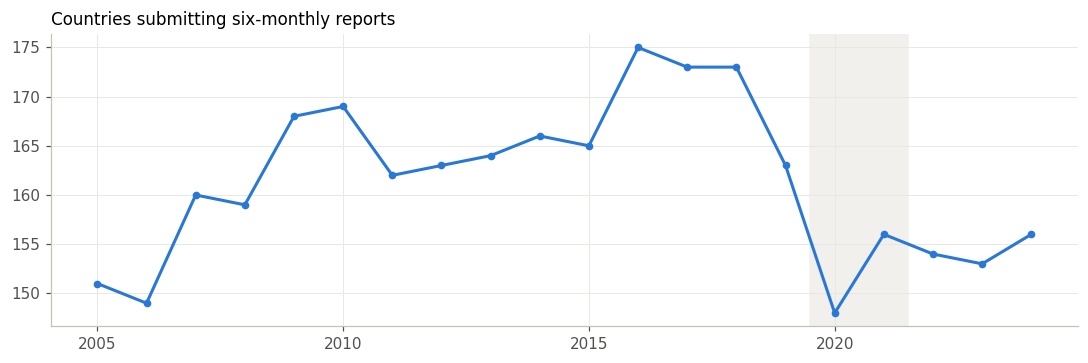

In [6]:
countries_per_year = smr.groupby("Year")["Country"].nunique()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.axvspan(2019.5, 2021.5, color="#f1f0ec", zorder=0)
ax.plot(countries_per_year.index, countries_per_year.values, marker="o", ms=4)
ax.set_title("Countries submitting six-monthly reports")
fmt_years(fig); plt.tight_layout(); plt.show()

### Data check B: a few reports dominate the raw totals
The largest single country-disease-years are mostly bee diseases (counted in hives) or one-off national reports. This is why the analysis works per disease, excludes bee diseases, and uses methods that are robust to spikes.

Top 1% of country-disease-years = 54% of all outbreaks


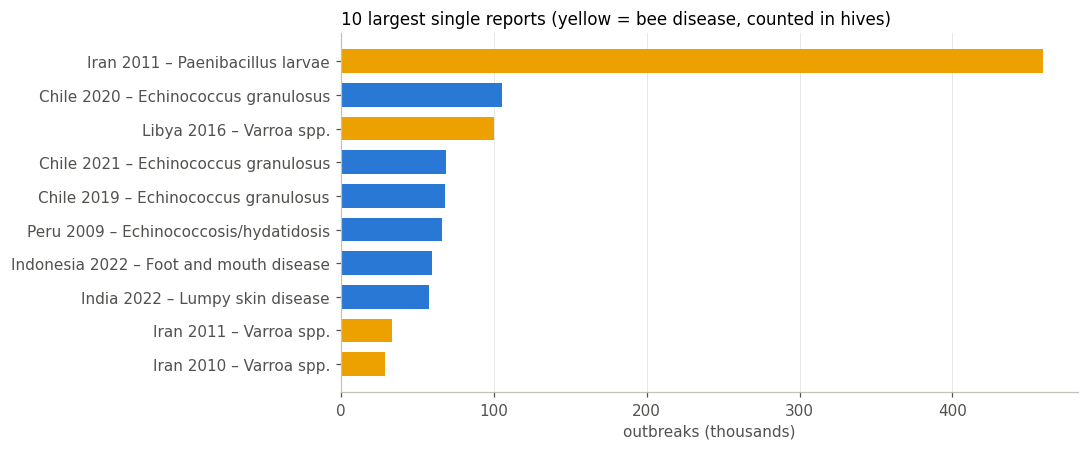

In [7]:
cdy = outbreaks.groupby(["Year", "Country", "Disease"])["New outbreaks"].sum().reset_index()
top1pct_share = cdy.nlargest(int(len(cdy) * 0.01), "New outbreaks")["New outbreaks"].sum() / cdy["New outbreaks"].sum()
print(f"Top 1% of country-disease-years = {top1pct_share:.0%} of all outbreaks")

top10 = cdy.nlargest(10, "New outbreaks").iloc[::-1]
labels = top10["Country"] + " " + top10["Year"].astype(str) + " – " + top10["Disease"].map(short)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(labels, top10["New outbreaks"] / 1000, height=0.7,
        color=np.where(top10["Disease"].isin(BEE_DISEASES), PALETTE[3], PALETTE[0]))
ax.set_xlabel("outbreaks (thousands)"); ax.grid(axis="y", visible=False)
ax.set_title("10 largest single reports (yellow = bee disease, counted in hives)")
plt.tight_layout(); plt.show()

# Part 1 — Trends and variations (Objective 1)

## 1.1 Long-term trends: which diseases are rising or falling?
For each key disease, semester outbreak counts (2005–2024) are modelled with **negative-binomial regression**: `outbreaks ~ time + half-year`, with log(reporting countries) as an offset. The time coefficient gives the **% change per year, per reporting country**.

A **Mann-Kendall test** (non-parametric, robust to single spikes) is run as a cross-check. A trend is called **robust** only when both tests are significant (p < 0.05) in the same direction.

In [8]:
SEMESTERS = pd.DataFrame([(y, h) for y in range(2005, 2025) for h in (0, 1)], columns=["Year", "half"])

def disease_series(disease, region=None):
    """Semester outbreak counts + number of reporting countries, for one disease (optionally one region)."""
    o, r = outbreaks[outbreaks["Disease"] == disease], reporting
    if region:
        o, r = o[o["World region"] == region], r[r["World region"] == region]
    y = o.groupby(["Year", "half"])["New outbreaks"].sum().rename("y")
    n = r.groupby(["Year", "half"])["n_rep"].sum()
    g = SEMESTERS.join(y, on=["Year", "half"]).join(n, on=["Year", "half"])
    g["y"] = g["y"].fillna(0)
    g["t"] = g["Year"] + g["half"] / 2 - 2005
    return g[g["n_rep"] > 0].reset_index(drop=True)

def trend_test(g):
    X = sm.add_constant(g[["t", "half"]])
    m = sm.NegativeBinomial(g["y"], X, offset=np.log(g["n_rep"])).fit(disp=0, maxiter=500)
    b, se = m.params["t"], m.bse["t"]
    tau, mk_p = stats.kendalltau(g["t"], g["y"] / g["n_rep"])
    return {"pct_per_year": np.exp(b) - 1, "lo": np.exp(b - 1.96 * se) - 1, "hi": np.exp(b + 1.96 * se) - 1,
            "p": m.pvalues["t"], "mk_tau": tau, "mk_p": mk_p,
            "jul_dec_vs_jan_jun": np.exp(m.params["half"]), "half_p": m.pvalues["half"]}

rows = []
for dz, label in KEY.items():
    for region in [None] + REGIONS:
        g = disease_series(dz, region)
        if (g["y"] > 0).sum() < 6:
            continue
        try:
            rows.append({"disease": label, "region": region or "Global", "outbreaks": int(g["y"].sum()), **trend_test(g)})
        except Exception:
            pass
trends = pd.DataFrame(rows)
trends["robust"] = (trends["p"] < 0.05) & (trends["mk_p"] < 0.05) & (np.sign(trends["pct_per_year"]) == np.sign(trends["mk_tau"]))
trends["direction"] = np.where(~trends["robust"], "no robust trend", np.where(trends["pct_per_year"] > 0, "rising", "falling"))

global_trends = trends[trends["region"] == "Global"].sort_values("pct_per_year").reset_index(drop=True)
global_trends.assign(**{c: global_trends[c].map("{:+.1%}".format) for c in ["pct_per_year", "lo", "hi"]}).round(3)

,disease,region,outbreaks,pct_per_year,lo,hi,p,mk_tau,mk_p,jul_dec_vs_jan_jun,half_p,robust,direction
0,Anthrax,Global,20253,-8.7%,-10.3%,-7.0%,0.000,-0.613,0.000,1.321,0.006,True,falling
1,Bovine babesiosis,Global,72844,-5.8%,-7.3%,-4.2%,0.000,-0.531,0.000,0.813,0.025,True,falling
2,Newcastle disease,Global,71789,-3.9%,-5.6%,-2.1%,0.000,-0.428,0.000,0.940,0.535,True,falling
3,Rabies,Global,225711,-3.8%,-4.4%,-3.1%,0.000,-0.703,0.000,0.987,0.729,True,falling
4,Sheep & goat pox,Global,43422,-2.2%,-4.2%,-0.2%,0.034,-0.274,0.013,0.967,0.780,True,falling
5,Bluetongue,Global,139353,-1.7%,-6.8%,+3.7%,0.536,0.085,0.442,13.152,0.000,False,no robust trend
6,Peste des petits ruminants,Global,53896,-1.6%,-3.8%,+0.7%,0.181,-0.172,0.118,0.973,0.818,False,no robust trend
7,Foot and mouth disease,Global,166203,+7.7%,+3.8%,+11.7%,0.000,0.028,0.798,0.802,0.354,False,no robust trend
8,Avian influenza (HPAI),Global,45171,+8.5%,+4.6%,+12.6%,0.000,0.223,0.043,0.492,0.006,True,rising
9,West Nile fever,Global,5802,+10.5%,+5.2%,+16.1%,0.000,0.308,0.005,18.599,0.000,True,rising


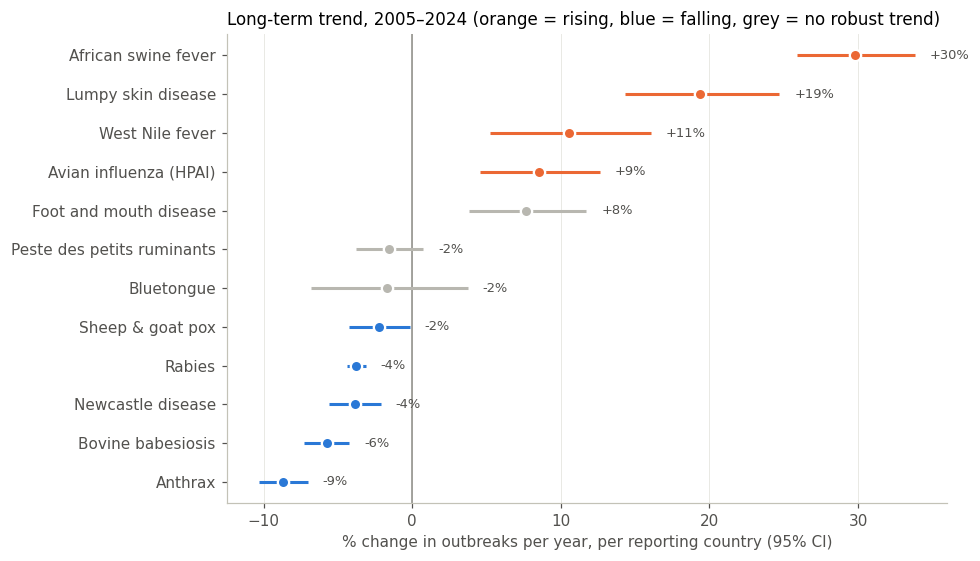

In [9]:
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.axvline(0, color="#8c8b85", lw=1)
for i, r in global_trends.iterrows():
    color = GREY if not r["robust"] else (UP if r["pct_per_year"] > 0 else DOWN)
    ax.hlines(i, r["lo"] * 100, r["hi"] * 100, color=color, lw=2)
    ax.scatter(r["pct_per_year"] * 100, i, s=55, color=color, zorder=3, edgecolor="white", linewidth=1.5)
    ax.text(r["hi"] * 100 + 1, i, f"{r['pct_per_year']:+.0%}", va="center", fontsize=8.5, color=MUTED)
ax.set_yticks(range(len(global_trends)), global_trends["disease"])
ax.set_xlabel("% change in outbreaks per year, per reporting country (95% CI)")
ax.set_title("Long-term trend, 2005–2024 (orange = rising, blue = falling, grey = no robust trend)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Regional variation in trends.** The same test, run per region. Cells show % change per year; faded cells are not robust. The same disease can move in different directions in different regions, e.g. FMD rising in Asia (Indonesia 2022) while falling elsewhere.

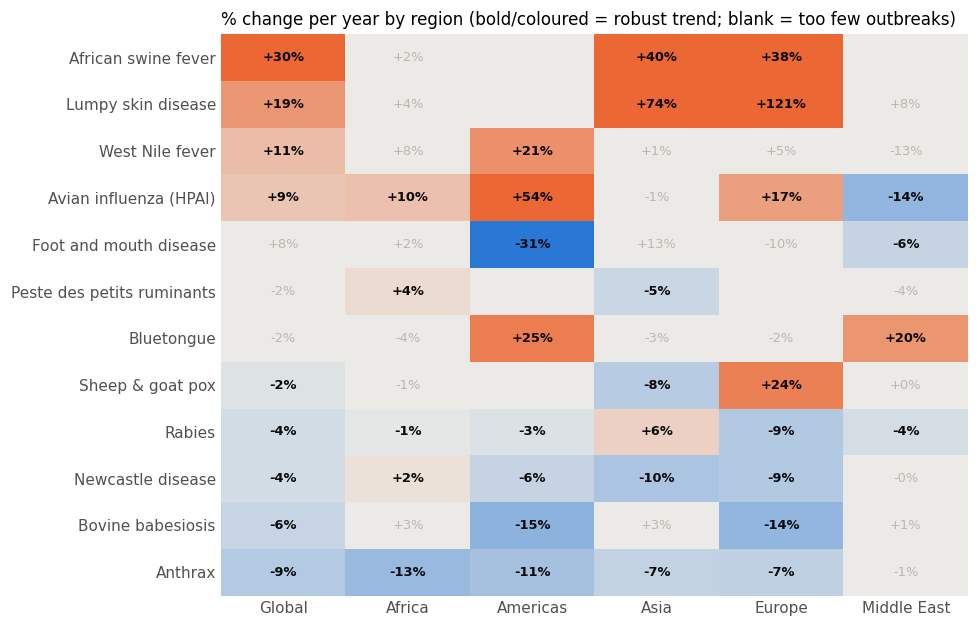

In [10]:
heat = trends.pivot(index="disease", columns="region", values="pct_per_year").reindex(
    index=global_trends["disease"][::-1], columns=["Global"] + REGIONS)
robust = trends.pivot(index="disease", columns="region", values="robust").reindex_like(heat).fillna(False).astype(bool)

from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
cmap = LinearSegmentedColormap.from_list("div", [DOWN, "#ecebe7", UP])
vals = heat.clip(-0.3, 0.3)
fig, ax = plt.subplots(figsize=(9, 5.8))
ax.imshow(np.where(robust, vals, 0), cmap=cmap, norm=TwoSlopeNorm(0, -0.3, 0.3), aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:+.0%}", ha="center", va="center", fontsize=8.5,
                    color=INK if robust.iat[i, j] else GREY, fontweight="bold" if robust.iat[i, j] else "normal")
ax.set_xticks(range(heat.shape[1]), heat.columns); ax.set_yticks(range(heat.shape[0]), heat.index)
ax.tick_params(length=0); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("% change per year by region (bold/coloured = robust trend; blank = too few outbreaks)")
plt.tight_layout(); plt.show()

## 1.2 What is normal, and what is a significant variation?
For each disease and region, a **surveillance baseline** estimates the expected number of outbreaks per semester. This uses the method behind European outbreak-detection systems (Farrington et al. 1996; Noufaily et al. 2013):
- quasi-Poisson regression with a smooth long-term trend + half-year (seasonal) effect + reporting-countries offset;
- past spikes are **down-weighted**, so earlier epidemics don't inflate what counts as "normal";
- a semester is a **significant variation** when outbreaks exceed the **99% upper threshold**.

Each series starts at the first semester with outbreaks in that region, since "normal" isn't defined before a disease arrives.

**Reading the charts:** grey line = expected; shaded band = normal range (up to the 99% threshold); black line = observed; red dots = significant variations.

In [11]:
TREND_TERMS = ["cr(t, df=4, constraints='center')", "t", "1"]  # flexible -> linear -> flat (fallbacks)

def _baseline_fit(g, trend, z):
    X = dmatrix(f"{trend} + half", g, return_type="dataframe")
    off = np.log(g["n_rep"])
    start = np.linalg.lstsq(X.values, np.log(g["y"] + 0.5) - off, rcond=None)[0]
    fit = lambda w: sm.GLM(g["y"], X, family=sm.families.Poisson(), offset=off, var_weights=w).fit(start_params=start, maxiter=200)
    w = np.ones(len(g))
    for _ in range(2):  # down-weight past spikes (Anscombe residuals > 1)
        m = fit(w); mu = m.fittedvalues
        phi = max(1, (w * (g["y"] - mu) ** 2 / mu).sum() / (len(g) - X.shape[1]))
        h = np.clip(1 - m.get_influence().hat_matrix_diag, 1e-3, None)
        r = 1.5 * (g["y"] ** (2 / 3) - mu ** (2 / 3)) / mu ** (1 / 6) / np.sqrt(phi * h)
        w = np.where(np.isfinite(r) & (r > 1), r ** -2.0, 1.0); w = w * len(w) / w.sum()
    m = fit(w); mu = m.fittedvalues
    if not np.all(np.isfinite(mu)) or mu.min() < 1e-8:
        raise ValueError("degenerate fit")
    phi = max(1, (w * (g["y"] - mu) ** 2 / mu).sum() / (len(g) - X.shape[1]))
    var_mu = mu ** 2 * np.einsum("ij,jk,ik->i", X.values, m.cov_params().values / m.scale, X.values) * phi
    upper = (mu ** (2 / 3) + z * (2 / 3) * mu ** (1 / 6) * np.sqrt(phi * mu + var_mu) / mu ** 0.5) ** 1.5
    return g.assign(expected=mu, upper=upper, flag=g["y"] > np.maximum(upper, 1))

def baseline(g, z=2.326):
    """Expected outbreaks + 99% upper threshold. Starts at the first semester with outbreaks."""
    g = g[g.index >= g.index[(g["y"] > 0).argmax()]].reset_index(drop=True)
    for trend in TREND_TERMS:
        try:
            return _baseline_fit(g, trend, z)
        except Exception:
            continue
    return None

# Main contributing country for each disease-region-semester (to explain flags)
top_country = (outbreaks.groupby(["Disease", "World region", "Year", "half", "Country"])["New outbreaks"].sum()
               .reset_index().sort_values("New outbreaks", ascending=False)
               .drop_duplicates(["Disease", "World region", "Year", "half"]))

baselines, flags, n_tests = {}, [], 0
for dz, label in KEY.items():
    for region in [None] + REGIONS:
        g = disease_series(dz, region)
        if (g["y"] > 0).sum() < 10:
            continue
        b = baseline(g)
        if b is None:
            continue
        baselines[(label, region or "Global")] = b
        n_tests += len(b)
        for _, r in b[b["flag"]].iterrows():
            tc = top_country[(top_country["Disease"] == dz) & (top_country["Year"] == r["Year"]) & (top_country["half"] == r["half"])]
            if region:
                tc = tc[tc["World region"] == region]
            flags.append({"disease": label, "region": region or "Global", "year": int(r["Year"]),
                          "semester": "Jan-Jun" if r["half"] == 0 else "Jul-Dec", "observed": int(r["y"]),
                          "expected": round(r["expected"]), "threshold": round(r["upper"]),
                          "x_expected": round(r["y"] / r["expected"], 1),
                          "main_country": tc["Country"].iloc[0] if len(tc) else ""})
flags = pd.DataFrame(flags)
print(f"{len(flags)} significant variations out of {n_tests:,} semester tests "
      f"(about {n_tests * 0.01:.0f} would be expected by chance at the 1% level)")

144 significant variations out of 2,543 semester tests (about 25 would be expected by chance at the 1% level)


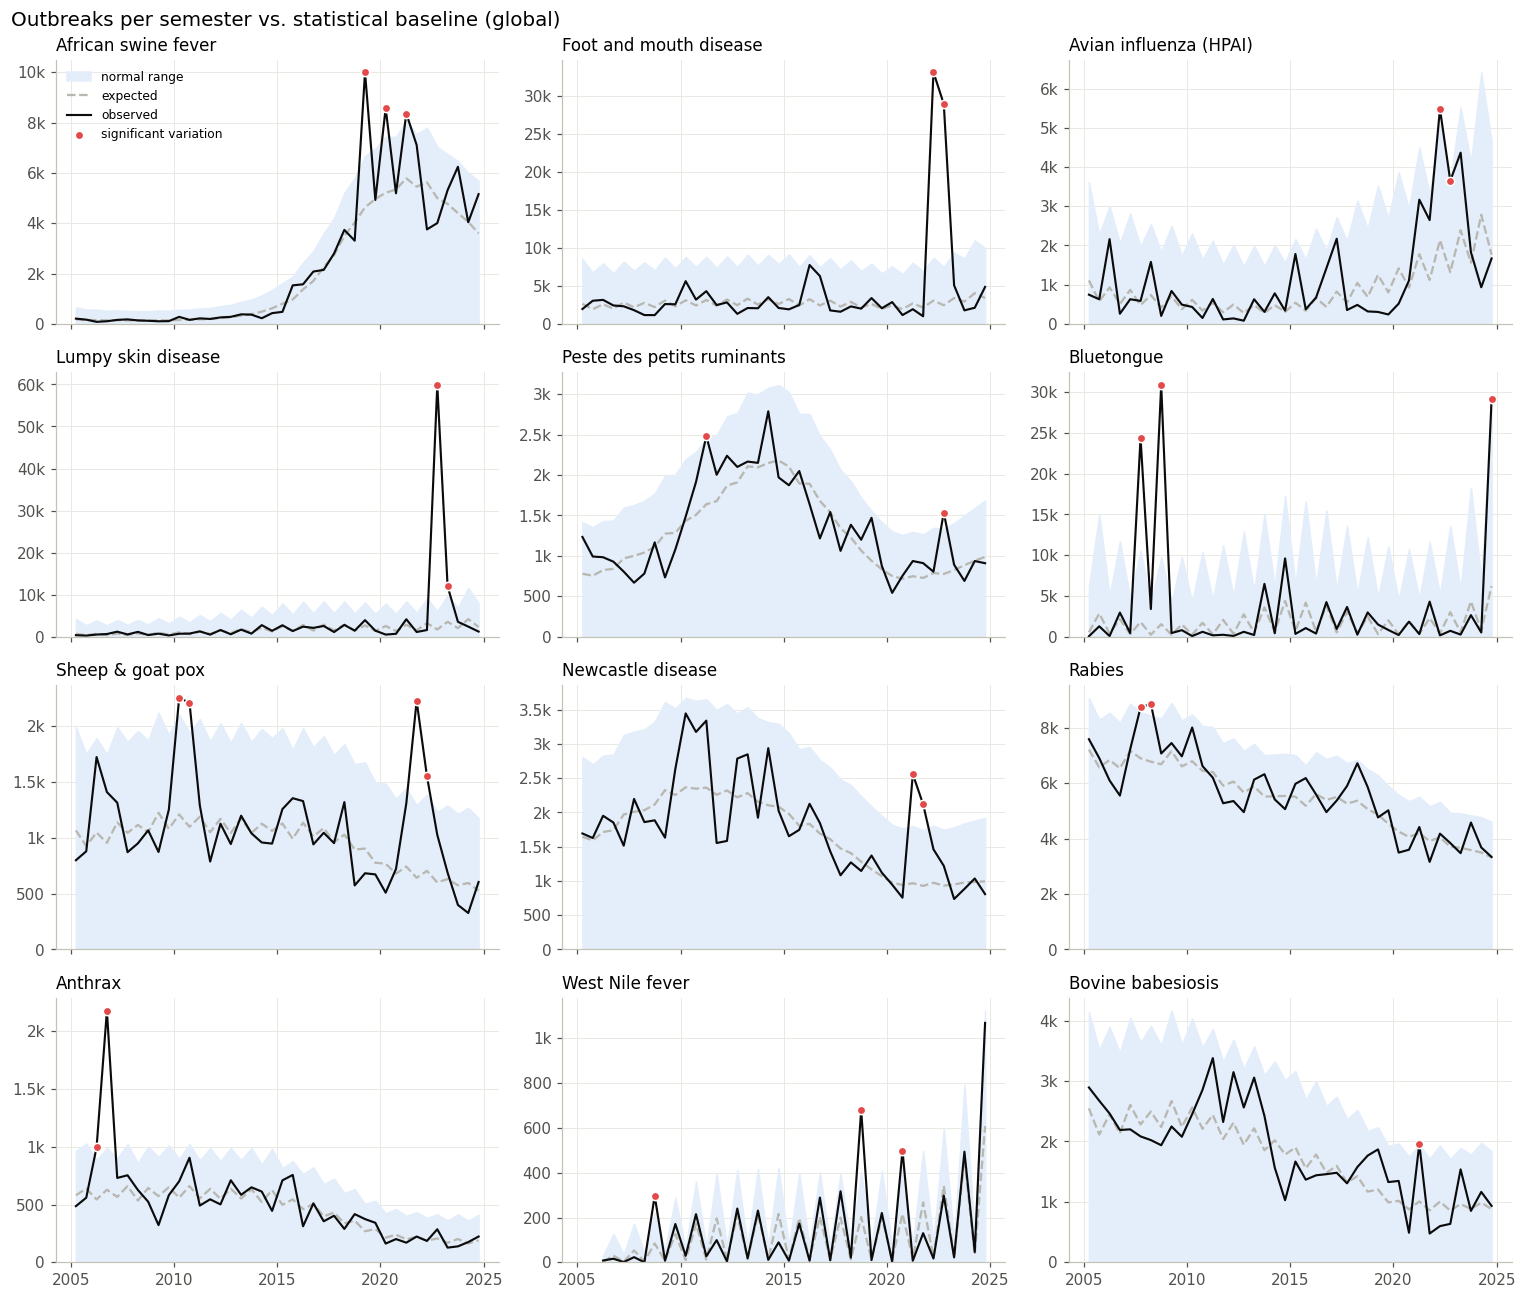

In [12]:
fig, axes = plt.subplots(4, 3, figsize=(14, 12), sharex=True)
for ax, label in zip(axes.flat, KEY.values()):
    b = baselines.get((label, "Global"))
    if b is None:
        ax.set_visible(False); continue
    x = b["Year"] + b["half"] / 2 + 0.25
    ax.fill_between(x, 0, b["upper"], color="#e4eefb", label="normal range")
    ax.plot(x, b["expected"], color=GREY, lw=1.5, ls="--", label="expected")
    ax.plot(x, b["y"], color=INK, lw=1.4, label="observed")
    f = b[b["flag"]]
    ax.scatter(f["Year"] + f["half"] / 2 + 0.25, f["y"], color=ALERT, s=30, zorder=4,
               edgecolor="white", linewidth=1, label="significant variation")
    ax.set_title(label); ax.set_ylim(0, None)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:g}k" if v >= 1000 else f"{v:.0f}"))
axes.flat[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("Outbreaks per semester vs. statistical baseline (global)", x=0.01, ha="left", fontsize=13)
fmt_years(fig); plt.tight_layout(); plt.show()

**All significant variations, global and regional.** `x_expected` = observed ÷ expected; `main_country` = the largest contributor that semester.

Most flags match documented epidemics:
- ASF in Asia 2019 (China/Vietnam)
- Bluetongue in Europe 2007–08 (BTV-8) and 2024 (BTV-3)
- FMD in Asia 2022 (Indonesia)
- LSD in Asia 2022 (India)
- HPAI 2021–22 (clade 2.3.4.4b panzootic)
- West Nile fever in Europe 2018

A cluster of flags in **2021** for endemic diseases (Newcastle disease, sheep & goat pox, babesiosis) coincides with the new WAHIS platform. These should be checked before being treated as real.

In [13]:
flags.sort_values(["x_expected"], ascending=False).reset_index(drop=True)

,disease,region,year,semester,observed,expected,threshold,x_expected,main_country
0,Avian influenza (HPAI),Europe,2016,Jul-Dec,758,4,684,187.8,Hungary
1,Avian influenza (HPAI),Europe,2017,Jan-Jun,1376,14,996,99.7,France
2,Lumpy skin disease,Asia,2022,Jul-Dec,59461,878,6414,67.7,India
3,Lumpy skin disease,Global,2022,Jul-Dec,59853,1704,6135,35.1,India
4,Avian influenza (HPAI),Americas,2015,Jan-Jun,247,7,168,34.9,United States of America
...,...,...,...,...,...,...,...,...,...
139,Rabies,Americas,2008,Jan-Jun,1345,1035,1276,1.3,Brazil
140,Rabies,Americas,2008,Jul-Dec,1278,1013,1251,1.3,Brazil
141,Rabies,Global,2008,Jan-Jun,8857,6769,8433,1.3,Russia
142,Rabies,Global,2007,Jul-Dec,8724,6892,8563,1.3,Russia


## 1.3 Geographic spread of transboundary diseases
Outbreak counts measure intensity. The number of **countries affected** measures spread, and it's robust to single large reports.

- **ASF:** ~20 → ~50 countries. Georgia 2007 → Russia → Baltics & Poland 2014 → China 2018 → SE Asia 2019 → Caribbean 2021 ([Rowlands 2008](https://wwwnc-origin.cdc.gov/eid/article/14/12/pdfs/08-0591.pdf); [EFSA 2017](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC7010137/); [Ge 2018](https://wwwnc.cdc.gov/eid/article/24/11/18-1274)).
- **LSD:** Middle East 2012–14 → Balkans 2015–16, where vaccination cut outbreaks 95% ([Broglia](https://svepm.org.uk/wp-content/uploads/2025/05/Broglia-Lumpy-skin-disease-epidemics-in-Europe-Assessment-of-diease-spread-and-vaccine-effectiveness.pdf)) → South & East Asia 2019–24 ([FAO](https://openknowledge.fao.org/items/ad54fb2c-c1f3-4dbb-af76-daf090261dd6/full)).
- **HPAI:** strain shift H5N1 → H5N8/H5N6 (2014–20) → new H5N1 clade 2.3.4.4b (2021+), with a jump in wild-bird reporting ([EFSA 2022](https://www.thepoultrysite.com/news/2022/10/worst-ever-avian-influenza-crisis-in-europe-raises-concerns-efsa)).

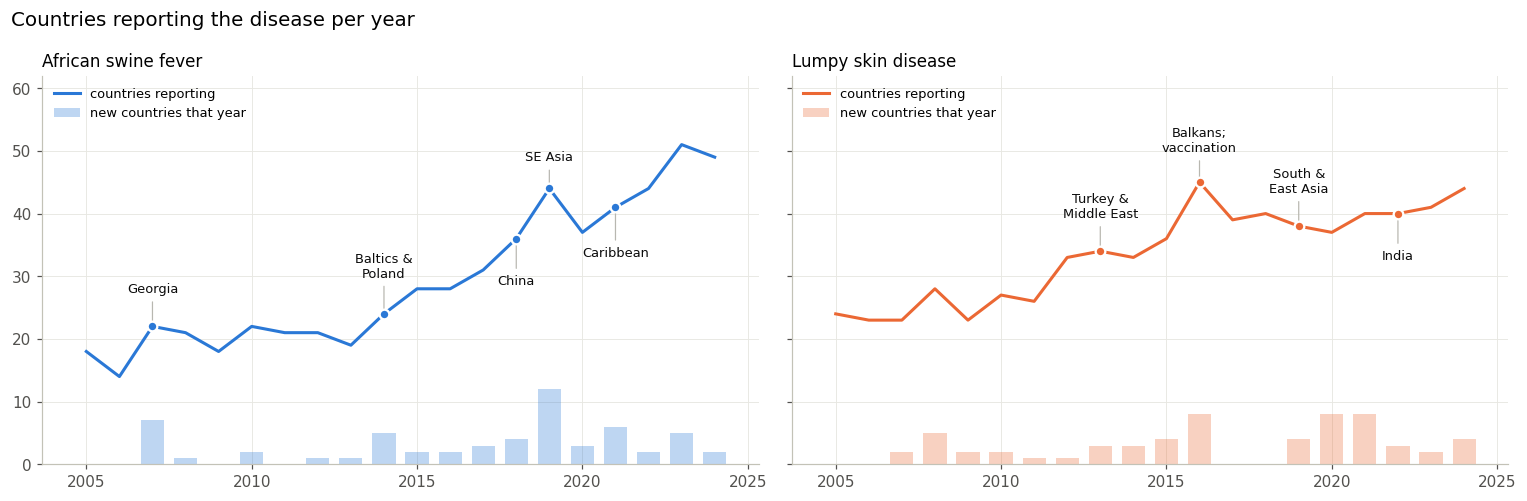

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
spread_specs = [
    ("African swine fever virus (Inf. with)", "African swine fever", PALETTE[0],
     {2007: ("Georgia", 22), 2014: ("Baltics &\nPoland", 24), 2018: ("China", -30), 2019: ("SE Asia", 18), 2021: ("Caribbean", -32)}),
    ("Lumpy skin disease virus (Inf. with)", "Lumpy skin disease", PALETTE[1],
     {2013: ("Turkey &\nMiddle East", 22), 2016: ("Balkans;\nvaccination", 20), 2019: ("South &\nEast Asia", 22), 2022: ("India", -30)}),
]
for ax, (dz, label, color, notes) in zip(axes, spread_specs):
    s = countries_with[dz]
    new = new_intros[new_intros["Disease"] == dz].groupby("Year").size().reindex(s.index, fill_value=0)
    ax.bar(new.index, new.values, color=color, alpha=0.3, width=0.7, label="new countries that year")
    ax.plot(s.index, s.values, color=color, label="countries reporting")
    milestones(ax, s, notes, color)
    ax.set_ylim(0, 62); ax.set_title(label); ax.legend(frameon=False, loc="upper left", fontsize=8.5)
fig.suptitle("Countries reporting the disease per year", x=0.01, ha="left", fontsize=13)
fmt_years(fig); plt.tight_layout(); plt.show()

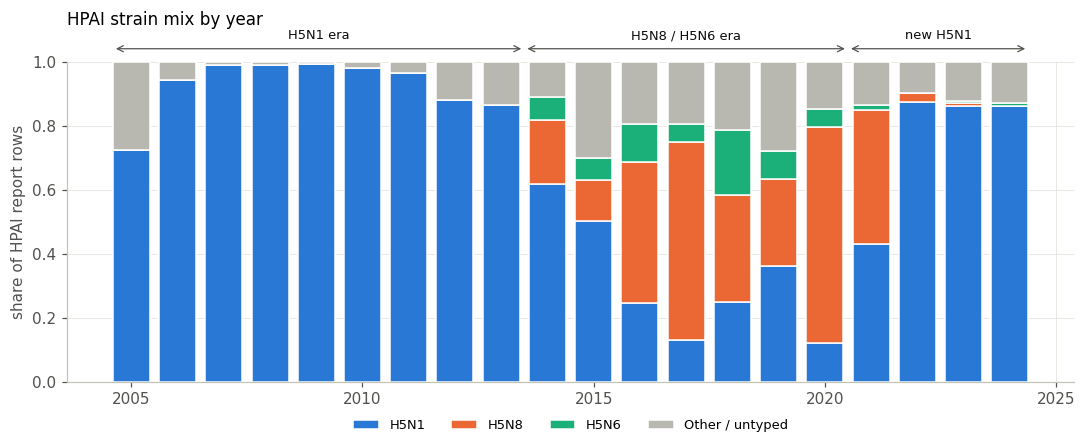

In [15]:
hpai = clean[clean["Disease"] == "HPAI"]
subtypes = ["H5N1", "H5N8", "H5N6"]
st = pd.crosstab(hpai["Year"], hpai["Serotype/Subtype/Genotype"].where(
    hpai["Serotype/Subtype/Genotype"].isin(subtypes), "Other / untyped"))[subtypes + ["Other / untyped"]]
st_share = st.div(st.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 4.2))
bottom = np.zeros(len(st_share))
for col, colr in zip(st_share.columns, PALETTE[:3] + [GREY]):
    ax.bar(st_share.index, st_share[col], bottom=bottom, color=colr, label=col, width=0.8, edgecolor="white", linewidth=1)
    bottom += st_share[col].values
for x0, x1, label in [(2004.6, 2013.5, "H5N1 era"), (2013.5, 2020.5, "H5N8 / H5N6 era"), (2020.5, 2024.4, "new H5N1")]:
    ax.annotate("", (x0, 1.04), (x1, 1.04), xycoords=("data", "axes fraction"), arrowprops=dict(arrowstyle="<->", color=MUTED, lw=0.8))
    ax.text((x0 + x1) / 2, 1.07, label, transform=ax.get_xaxis_transform(), ha="center", fontsize=8.5, color=INK)
ax.set_ylim(0, 1); ax.set_ylabel("share of HPAI report rows")
ax.set_title("HPAI strain mix by year", pad=24)
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=8.5)
fmt_years(fig); plt.tight_layout(); plt.show()

## 1.4 Seasonal variation
Share of outbreaks reported in Jan–Jun (0.5 = no seasonal pattern). Insect-borne diseases peak in Jul–Dec (northern-hemisphere vector season): bluetongue 93%, LSD 61%. HPAI in poultry peaks in Jan–Jun (winter migration). In the trend models (1.1, columns `jul_dec_vs_jan_jun` and `half_p`), the half-year effect is significant for bluetongue and West Nile fever (much higher in Jul–Dec), anthrax (higher in Jul–Dec), and HPAI and babesiosis (higher in Jan–Jun).

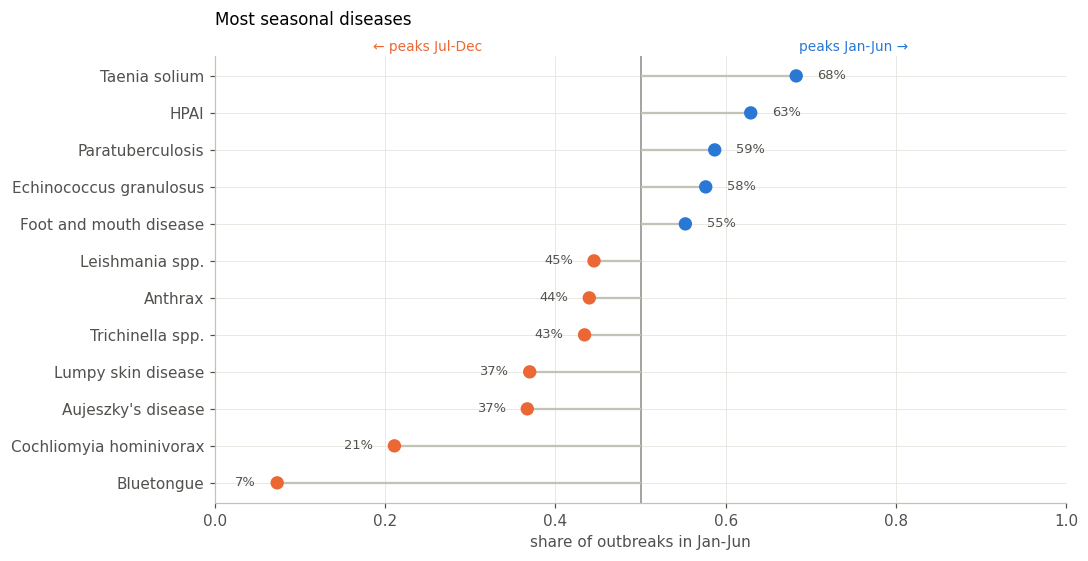

In [16]:
sea = (outbreaks[~outbreaks["Disease"].isin(BEE_DISEASES)]
       .assign(Half=lambda d: np.where(d["half"] == 0, "Jan-Jun", "Jul-Dec"))
       .pivot_table(index="Disease", columns="Half", values="New outbreaks", aggfunc="sum").fillna(0))
sea = sea[sea.sum(axis=1) > 20000]
sea["share"] = sea["Jan-Jun"] / sea.sum(axis=1)
show = pd.concat([sea.sort_values("share").head(7), sea.sort_values("share").tail(5)])

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.axvline(0.5, color="#8c8b85", lw=1)
ax.hlines(range(len(show)), 0.5, show["share"], color="#c3c2b7", lw=1.5)
ax.scatter(show["share"], range(len(show)), s=60, zorder=3, color=[UP if v < 0.5 else DOWN for v in show["share"]])
for i, v in enumerate(show["share"]):
    ax.text(v + (0.025 if v >= 0.5 else -0.025), i, f"{v:.0%}", va="center",
            ha="left" if v >= 0.5 else "right", fontsize=8.5, color=MUTED)
ax.set_yticks(range(len(show)), [short(d) for d in show.index])
ax.set_xlim(0, 1); ax.set_xlabel("share of outbreaks in Jan-Jun")
ax.text(0.25, 1.01, "← peaks Jul-Dec", transform=ax.get_xaxis_transform(), ha="center", fontsize=9, color=UP)
ax.text(0.75, 1.01, "peaks Jan-Jun →", transform=ax.get_xaxis_transform(), ha="center", fontsize=9, color=DOWN)
ax.set_title("Most seasonal diseases", pad=20)
plt.tight_layout(); plt.show()

# Part 2 — Association with climate (Objective 2)

## 2.1 Climate data
**WorldClim 2.1 historical monthly weather** (CRU-TS 4.09, 10 arc-min; Fick & Hijmans 2017; Harris et al. 2020): monthly minimum and maximum temperature and precipitation, 2005–2024. `prepare_climate.py` averages each month over each country (area-weighted, Natural Earth borders).

For each country and semester:
- **Temperature** = mean of (tmin + tmax) / 2.
- **Precipitation** = total over the six months.
- Both are turned into **anomalies**: standard deviations from that country's own 2005–2024 average for the same half-year. A +1 means "one SD warmer/wetter than normal for that country at that time of year".
- **Lagged** anomalies (previous semester) test for an *early* signal.

193 countries, 6,140 country-semesters with both WAHIS reports and climate data


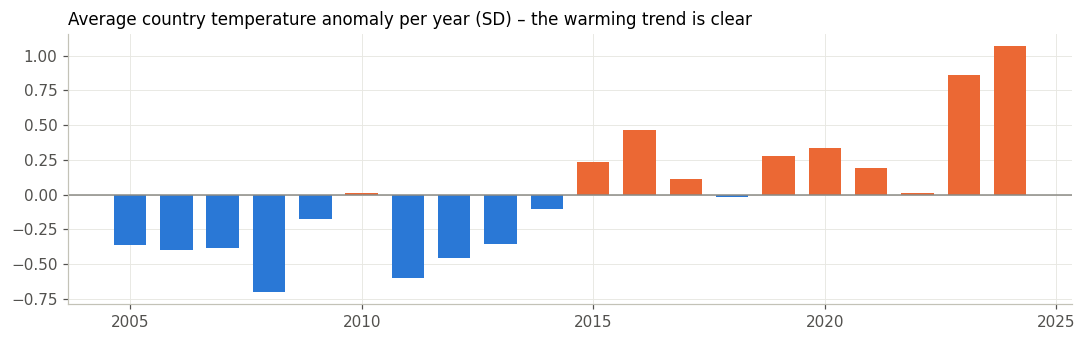

In [17]:
climate = pd.read_csv("data/climate_country_month.csv")
iso = pd.read_csv("data/wahis_country_iso3.csv")

climate["half"] = (climate["month"] > 6).astype(int)
climate["tmean"] = (climate["tmin"] + climate["tmax"]) / 2
clim_sem = (climate.groupby(["iso3", "year", "half"])
            .agg(tmean=("tmean", "mean"), prec=("prec", "sum")).reset_index()
            .rename(columns={"year": "Year"}))
for v in ["tmean", "prec"]:
    grp = clim_sem.groupby(["iso3", "half"])[v]
    clim_sem[f"{v}_anom"] = ((clim_sem[v] - grp.transform("mean")) / grp.transform("std")).replace([np.inf, -np.inf], np.nan)
# A few remote islands (e.g. Falklands, South Georgia) have no year-to-year variation in the CRU data -> no anomaly
clim_sem = clim_sem.sort_values(["iso3", "Year", "half"])
for v in ["tmean_anom", "prec_anom"]:
    clim_sem[f"{v}_lag1"] = clim_sem.groupby("iso3")[v].shift(1)

CLIM_VARS = ["tmean_anom", "prec_anom", "tmean_anom_lag1", "prec_anom_lag1"]
CLIM_LABELS = {"tmean_anom": "Temperature (same semester)", "prec_anom": "Precipitation (same semester)",
               "tmean_anom_lag1": "Temperature (previous semester)", "prec_anom_lag1": "Precipitation (previous semester)"}

# Panel: every country-semester with a six-monthly report, joined to climate
reported = smr[["Country", "Year", "half"]].drop_duplicates().merge(iso, on="Country").merge(clim_sem, on=["iso3", "Year", "half"])
country_sem = outbreaks.groupby(["Country", "Year", "half", "Disease"])["New outbreaks"].sum().rename("y").reset_index()
print(f"{reported['Country'].nunique()} countries, {len(reported):,} country-semesters with both WAHIS reports and climate data")

def disease_panel(disease):
    """Country-semester panel for one disease (0 = reported, no outbreaks). Countries never affected are dropped."""
    p = reported.merge(country_sem[country_sem["Disease"] == disease].drop(columns="Disease"),
                       on=["Country", "Year", "half"], how="left").fillna({"y": 0})
    return p[p.groupby("Country")["y"].transform("sum") > 0].dropna(subset=CLIM_VARS)

# Global land temperature anomaly over time (sanity check: warming trend should be visible)
glob = clim_sem.groupby("Year")[["tmean_anom", "prec_anom"]].mean()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.axhline(0, color="#8c8b85", lw=1)
ax.bar(glob.index, glob["tmean_anom"], color=[UP if v > 0 else DOWN for v in glob["tmean_anom"]], width=0.7)
ax.set_title("Average country temperature anomaly per year (SD) – the warming trend is clear")
fmt_years(fig); plt.tight_layout(); plt.show()

## 2.2 Statistical association between climate and outbreaks
For each key disease, a **Poisson fixed-effects regression** (PPML) on the country × semester panel:

`outbreaks ~ temp anomaly + precip anomaly + temp anomaly (prev. semester) + precip anomaly (prev. semester) + country + year + half-year`

- **Country effects** remove fixed differences between countries (size, farming systems, reporting habits).
- **Year effects** remove global shocks and trends (including the 2020 reporting drop and the warming trend).
- So the climate coefficients measure: *is a country's outbreak count higher in semesters that are unusually warm/wet for that country?*
- Results are **incidence rate ratios (IRR) per +1 SD**. 95% CIs are clustered by country. p-values are corrected for 48 tests (Benjamini-Hochberg, q < 0.05).

In [18]:
FORMULA = "y ~ " + " + ".join(CLIM_VARS) + " + C(Country) + C(Year) + C(half)"

def climate_model(p, family=sm.families.Poisson(), outcome="y"):
    return smf.glm(FORMULA.replace("y ~", f"{outcome} ~"), p, family=family).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(p["Country"])[0]}, maxiter=200)

rows = []
for dz, label in KEY.items():
    p = disease_panel(dz)
    m = climate_model(p)
    for v in CLIM_VARS:
        b, se = m.params[v], m.bse[v]
        rows.append({"disease": label, "variable": v, "IRR": np.exp(b), "lo": np.exp(b - 1.96 * se),
                     "hi": np.exp(b + 1.96 * se), "p": m.pvalues[v], "countries": p["Country"].nunique(), "obs": len(p)})
assoc = pd.DataFrame(rows)
assoc["q"] = multipletests(assoc["p"], method="fdr_bh")[1]
assoc["significant"] = assoc["q"] < 0.05
assoc[assoc["significant"]].round(3)

,disease,variable,IRR,lo,hi,p,countries,obs,q,significant
4,Foot and mouth disease,tmean_anom,0.739,0.622,0.878,0.001,92,3172,0.007,True
9,Avian influenza (HPAI),prec_anom,0.758,0.679,0.846,0.000,119,4354,0.000,True
13,Lumpy skin disease,prec_anom,1.739,1.274,2.375,0.000,85,2975,0.007,True
15,Lumpy skin disease,prec_anom_lag1,1.828,1.239,2.696,0.002,85,2975,0.023,True
23,Bluetongue,prec_anom_lag1,1.975,1.675,2.328,0.000,69,2573,0.000,True


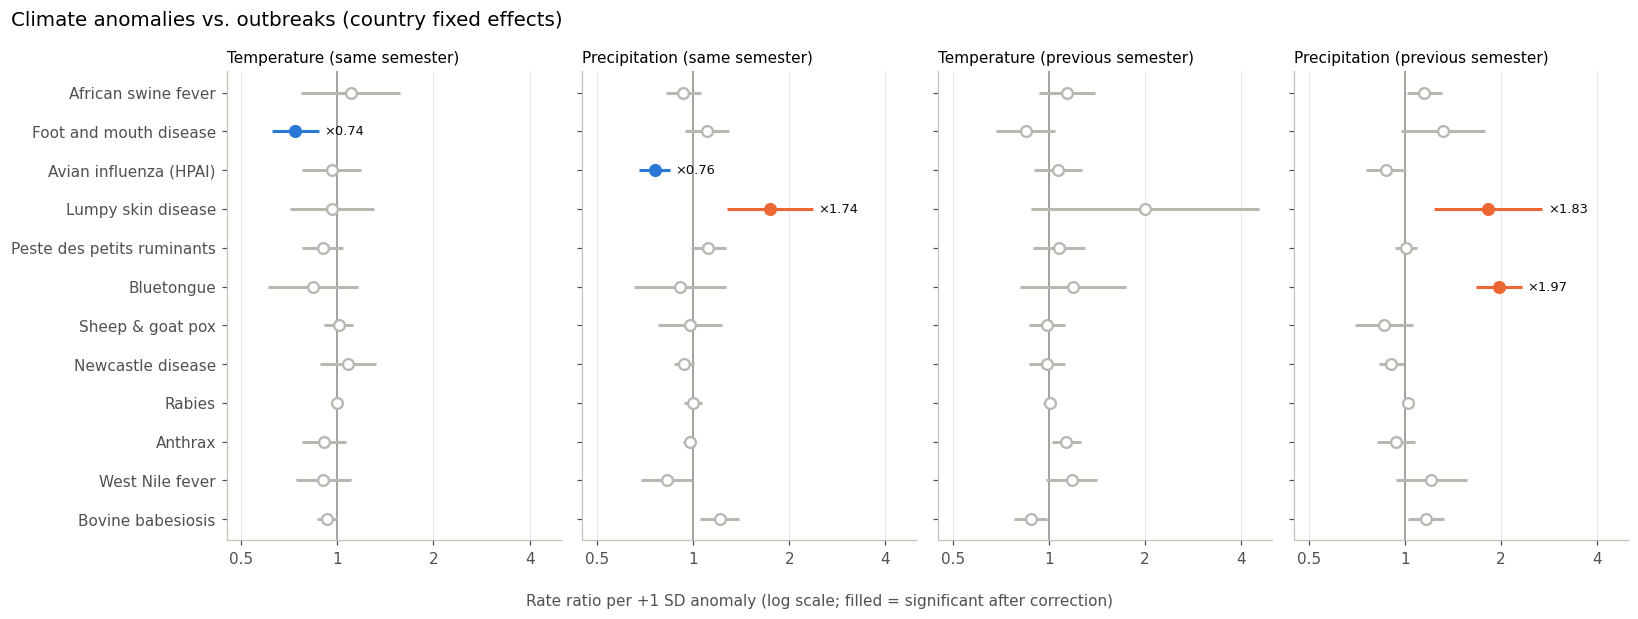

In [19]:
order = list(KEY.values())[::-1]
fig, axes = plt.subplots(1, 4, figsize=(15, 5.6), sharey=True)
for ax, v in zip(axes, CLIM_VARS):
    a = assoc[assoc["variable"] == v].set_index("disease").reindex(order)
    ax.axvline(1, color="#8c8b85", lw=1)
    for i, (_, r) in enumerate(a.iterrows()):
        color = GREY if not r["significant"] else (UP if r["IRR"] > 1 else DOWN)
        ax.hlines(i, r["lo"], r["hi"], color=color, lw=2)
        ax.scatter(r["IRR"], i, s=50, zorder=3, color=color if r["significant"] else "white", edgecolor=color, linewidth=1.5)
        if r["significant"]:
            ax.text(r["hi"] * 1.04, i, f"×{r['IRR']:.2f}", va="center", fontsize=8.5, color=INK)
    ax.set_xscale("log"); ax.set_xlim(0.45, 5)
    ax.set_xticks([0.5, 1, 2, 4], ["0.5", "1", "2", "4"]); ax.minorticks_off()
    ax.set_title(CLIM_LABELS[v], fontsize=10); ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(order)), order)
fig.supxlabel("Rate ratio per +1 SD anomaly (log scale; filled = significant after correction)", fontsize=10, color=MUTED)
fig.suptitle("Climate anomalies vs. outbreaks (country fixed effects)", x=0.01, ha="left", fontsize=13)
plt.tight_layout(); plt.show()

### Robustness checks
A finding should not depend on one country or on how outbreaks are counted. For each significant association:
1. **Drop the largest contributing country** and refit.
2. **Outcome = any outbreaks (yes/no)** instead of the count (fixed-effects logistic regression, odds ratio).

In [20]:
robust_rows = []
for _, r in assoc[assoc["significant"]].iterrows():
    dz = {v: k for k, v in KEY.items()}[r["disease"]]
    p = disease_panel(dz)
    top = p.groupby("Country")["y"].sum().idxmax()
    m_drop = climate_model(p[p["Country"] != top])
    pb = p.assign(any_outbreak=(p["y"] > 0).astype(int))
    pb = pb[pb.groupby("Country")["any_outbreak"].transform("std") > 0]
    m_bin = climate_model(pb, sm.families.Binomial(), outcome="any_outbreak")
    v = r["variable"]
    robust_rows.append({
        "disease": r["disease"], "variable": CLIM_LABELS[v], "IRR (main)": round(r["IRR"], 2),
        "dropped country": top, "IRR without it": round(np.exp(m_drop.params[v]), 2), "p without it": round(m_drop.pvalues[v], 3),
        "OR (any outbreak)": round(np.exp(m_bin.params[v]), 2), "p (any outbreak)": round(m_bin.pvalues[v], 3),
    })
robustness = pd.DataFrame(robust_rows)
robustness["holds up"] = (robustness["p without it"] < 0.05) & (np.sign(np.log(robustness["IRR without it"])) == np.sign(np.log(robustness["IRR (main)"])))
robustness

,disease,variable,IRR (main),dropped country,IRR without it,p without it,OR (any outbreak),p (any outbreak),holds up
0,Foot and mouth disease,Temperature (same semester),0.74,Indonesia,0.85,0.002,0.86,0.019,True
1,Avian influenza (HPAI),Precipitation (same semester),0.76,Indonesia,0.79,0.000,0.88,0.013,True
2,Lumpy skin disease,Precipitation (same semester),1.74,India,1.11,0.196,1.05,0.339,False
3,Lumpy skin disease,Precipitation (previous semester),1.83,India,1.32,0.006,1.20,0.002,True
4,Bluetongue,Precipitation (previous semester),1.97,France,1.73,0.000,1.27,0.002,True


### Interpretation
- **Bluetongue ↔ wetter previous semester (robust).** Bluetongue is spread by *Culicoides* midges, which breed in wet ground and dung. A wet semester lets midge populations build up before the next transmission season. This is the clearest climate signal, and it comes *before* the outbreaks.
- **Lumpy skin disease ↔ wetter previous semester (robust).** LSD is spread mechanically by biting flies, mosquitoes and ticks, which also increase after wet periods. The *same-semester* rainfall effect is driven by India's 2022 epidemic and does not survive dropping India.
- **FMD ↔ cooler semesters (robust).** FMD virus survives longer in cool, humid conditions, which helps transmission through the environment and the air.
- **HPAI ↔ drier semesters (robust).** One possible explanation: dry conditions concentrate waterfowl on fewer wetlands, increasing contact between wild birds and poultry. This needs finer-scale data to confirm.
- **No association** for rabies, PPR, sheep & goat pox, Newcastle disease, ASF or West Nile fever (after correction). Their drivers are mostly human/animal movement, vaccination and wildlife, not climate.

**Limits:** country-level averages blur climate in large countries (Russia, China, Brazil), and six-month periods are coarse. This is an **association**, not proof of causation.

# Part 3 — Can this give an early warning? (Objective 3)

## 3.1 Does climate improve prediction of the next semester?
A useful early warning must predict **before** outbreaks happen. Test design:
- **Target:** a "surge" semester for a country (outbreaks above that country's 75th percentile).
- **Baseline model:** information available at the end of the previous semester — last semester's outbreaks, whether it was a surge, and which half of the year is next.
- **Climate model:** baseline + previous-semester temperature and precipitation anomalies.
- **Train** on 2005–2018, **test** on 2019–2024 (out of sample). Accuracy = AUC (0.5 = coin flip, 1 = perfect), with a bootstrap 95% CI for the gain from adding climate.

In [21]:
def early_warning(disease, seed=0):
    p = reported.merge(country_sem[country_sem["Disease"] == disease].drop(columns="Disease"),
                       on=["Country", "Year", "half"], how="left").fillna({"y": 0})
    p = p[p.groupby("Country")["y"].transform("sum") > 0].sort_values(["Country", "Year", "half"])
    q75 = p.groupby("Country")["y"].transform(lambda s: s.quantile(0.75))
    p["surge"] = ((p["y"] > q75) & (p["y"] > 0)).astype(int)
    p["log_y_prev"] = np.log1p(p.groupby("Country")["y"].shift(1))
    p["surge_prev"] = p.groupby("Country")["surge"].shift(1)
    p = p.dropna(subset=["log_y_prev", "surge_prev", "tmean_anom_lag1", "prec_anom_lag1"])
    base = ["log_y_prev", "surge_prev", "half"]
    with_climate = base + ["tmean_anom_lag1", "prec_anom_lag1"]
    train, test = p[p["Year"] <= 2018], p[p["Year"] >= 2019]
    pred = {name: LogisticRegression(max_iter=1000).fit(train[cols], train["surge"]).predict_proba(test[cols])[:, 1]
            for name, cols in [("base", base), ("climate", with_climate)]}
    y = test["surge"].values
    rng, gains = np.random.default_rng(seed), []
    for _ in range(500):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            gains.append(roc_auc_score(y[i], pred["climate"][i]) - roc_auc_score(y[i], pred["base"][i]))
    return {"AUC baseline": roc_auc_score(y, pred["base"]), "AUC + climate": roc_auc_score(y, pred["climate"]),
            "gain lo": np.percentile(gains, 2.5), "gain hi": np.percentile(gains, 97.5), "test semesters": len(y)}

ew = pd.DataFrame({label: early_warning(dz) for dz, label in KEY.items()}).T
ew["gain"] = ew["AUC + climate"] - ew["AUC baseline"]
ew["climate helps?"] = np.where(ew["gain lo"] > 0, "yes", "no")
ew.round(3)

,AUC baseline,AUC + climate,gain lo,gain hi,test semesters,gain,climate helps?
African swine fever,0.768,0.774,-0.001,0.014,783.0,0.006,no
Foot and mouth disease,0.758,0.761,-0.005,0.013,914.0,0.004,no
Avian influenza (HPAI),0.752,0.751,-0.010,0.006,1318.0,-0.001,no
Lumpy skin disease,0.720,0.712,-0.028,0.010,863.0,-0.008,no
Peste des petits ruminants,0.683,0.683,-0.011,0.011,586.0,0.000,no
Bluetongue,0.712,0.710,-0.032,0.027,780.0,-0.002,no
Sheep & goat pox,0.744,0.755,-0.011,0.031,578.0,0.011,no
Newcastle disease,0.770,0.766,-0.015,0.005,1341.0,-0.005,no
Rabies,0.749,0.747,-0.008,0.002,1493.0,-0.003,no
Anthrax,0.659,0.659,-0.019,0.020,1126.0,-0.000,no


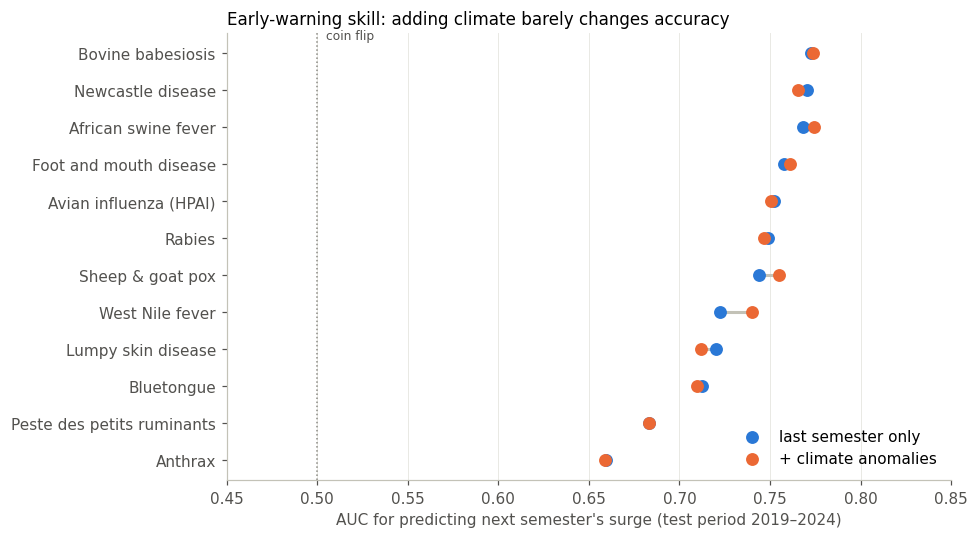

In [22]:
e = ew.sort_values("AUC baseline")
fig, ax = plt.subplots(figsize=(9, 5))
for i, (label, r) in enumerate(e.iterrows()):
    ax.plot([r["AUC baseline"], r["AUC + climate"]], [i, i], color="#c3c2b7", lw=2)
    ax.scatter(r["AUC baseline"], i, s=55, color=PALETTE[0], zorder=3, label="last semester only" if i == 0 else None)
    ax.scatter(r["AUC + climate"], i, s=55, color=PALETTE[1], zorder=3, label="+ climate anomalies" if i == 0 else None)
ax.axvline(0.5, color="#8c8b85", lw=1, ls=":")
ax.text(0.505, len(e) - 0.6, "coin flip", fontsize=8, color=MUTED)
ax.set_yticks(range(len(e)), e.index); ax.set_xlim(0.45, 0.85)
ax.set_xlabel("AUC for predicting next semester's surge (test period 2019–2024)")
ax.set_title("Early-warning skill: adding climate barely changes accuracy")
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Result.** Last semester's situation alone predicts next-semester surges reasonably well (AUC ≈ 0.66–0.77). **Adding climate anomalies does not improve this for any disease** (gain ≈ 0, all 95% CIs include 0).

The climate associations in Part 2 are real but small compared with the main driver, which is whether the disease is already circulating. At **country × semester** resolution, climate can't serve as a stand-alone early-warning trigger.

## 3.2 What *can* be used as early warning
1. **The statistical baseline as an alert threshold (Part 1.2).** Each country/region can compare each new report against its expected range. Exceeding the 99% threshold is an objective trigger for investigation. This is how ECDC- and UKHSA-style surveillance systems flag outbreaks.
2. **A climate watch list for insect-borne diseases.** For bluetongue and LSD, a wetter-than-normal semester raises next semester's expected outbreaks. The list below ranks countries with a history of the disease by their **latest** precipitation anomaly (Jul–Dec 2024 → risk for Jan–Jun 2025). It's a prompt for vector surveillance and vaccination readiness, not a forecast.

The relative risk uses the conservative effect size (largest country removed: bluetongue ×1.73, LSD ×1.32 per SD), caps anomalies at ±2 SD, and only lists countries with ≥5 outbreaks in 2015–24. Rainfall anomalies in very dry countries (e.g. Oman, Libya) can be large from small absolute changes, so read those with care.

In [23]:
latest = clim_sem[(clim_sem["Year"] == 2024) & (clim_sem["half"] == 1)][["iso3", "prec_anom", "tmean_anom"]]
watch = []
for dz in ["Bluetongue virus (Inf. with)", "Lumpy skin disease virus (Inf. with)"]:
    # Conservative effect size: the estimate without the largest country (robustness check)
    irr = robustness[(robustness["disease"] == KEY[dz]) & (robustness["variable"] == CLIM_LABELS["prec_anom_lag1"])]["IRR without it"].iloc[0]
    affected = (country_sem[(country_sem["Disease"] == dz) & (country_sem["Year"] >= 2015) & (country_sem["y"] > 0)]
                .groupby("Country")["y"].sum().rename("outbreaks 2015-24").reset_index())
    affected = affected[affected["outbreaks 2015-24"] >= 5]
    w = affected.merge(iso, on="Country").merge(latest, on="iso3")
    w["rain anomaly Jul-Dec 2024 (SD)"] = w["prec_anom"].round(2)
    w["relative risk Jan-Jun 2025"] = (irr ** w["prec_anom"].clip(-2, 2)).round(2)  # cap: beyond ±2 SD is extrapolation
    w.insert(0, "disease", KEY[dz])
    watch.append(w.sort_values("relative risk Jan-Jun 2025", ascending=False).head(10)
                 [["disease", "Country", "outbreaks 2015-24", "rain anomaly Jul-Dec 2024 (SD)", "relative risk Jan-Jun 2025"]])
watch_list = pd.concat(watch, ignore_index=True)
watch_list

,disease,Country,outbreaks 2015-24,rain anomaly Jul-Dec 2024 (SD),relative risk Jan-Jun 2025
0,Bluetongue,Oman,6.0,3.67,2.99
1,Bluetongue,Libya,53.0,1.94,2.90
2,Bluetongue,India,153.0,1.33,2.07
3,Bluetongue,Norway,92.0,1.19,1.92
4,Bluetongue,Lesotho,116.0,1.10,1.83
5,Bluetongue,Luxembourg,27.0,0.78,1.54
6,Bluetongue,Netherlands,34.0,0.55,1.35
7,Bluetongue,Madagascar,16.0,0.54,1.35
8,Bluetongue,Belgium,35.0,0.46,1.29
9,Bluetongue,Germany,15904.0,0.39,1.24


# Conclusions

**Objective 1 – Trends and variations**
- Per reporting country, outbreaks are **rising** for African swine fever (+30%/yr), lumpy skin disease (+19%/yr), West Nile fever (+11%/yr) and HPAI (+9%/yr). They are **falling** for rabies, anthrax, Newcastle disease and bovine babesiosis. Trends differ by region (heatmap, 1.1).
- "Normal" is defined by a surveillance baseline for each disease and region. It flags ~140 semesters as significant variations (vs. ~25 expected by chance). The largest match documented epidemics (ASF Asia 2019, FMD Indonesia 2022, LSD India 2022, bluetongue Europe 2007–08 and 2024, HPAI 2021–22).
- Spread of transboundary diseases is the dominant long-term pattern: ASF ~20 → ~50 countries, LSD out of Africa into Europe and Asia, and HPAI's shift to clade 2.3.4.4b with wild-bird spread.
- Seasonality is strong for insect-borne diseases (Jul–Dec) and HPAI (Jan–Jun).

**Objective 2 – Climate association**
- There are statistically significant, robust associations for **bluetongue** and **lumpy skin disease** (more outbreaks after a wet semester), **FMD** (more in cooler semesters) and **HPAI** (more in drier semesters). There is no association for most other diseases.

**Objective 3 – Early warning**
- At country × semester resolution, climate anomalies **do not add predictive skill** beyond last semester's disease situation.
- Two practical outputs remain: the baseline threshold as an objective alert trigger, and a climate watch list for insect-borne diseases.
- A stronger climate early warning would need **monthly, sub-national** data (WAHIS administrative divisions + WorldClim at 2.5′), and vector-specific indices (e.g. midge-suitability from temperature + rainfall).

**Limitations**
- WAHIS is a passive reporting system, so changes in surveillance and reporting can look like changes in disease. This was partly controlled with the reporting offset and year effects.
- Six-month periods and country averages are coarse.
- Results show statistical association, not causation.
- Some flagged variations (e.g. UK bovine TB 2024, Chile echinococcosis 2019–21, endemic diseases in 2021) are likely reporting changes.

## Additional EDA: overall trends and leading diseases
Reuses the existing audited EDA helper for two complementary views. The original team analysis above is retained. This supplement uses its own summary selection, so totals may differ; it does not revalidate the earlier model conclusions.

In [ ]:
from pathlib import Path
import sys
root = Path.cwd() if Path('WAHIS_data.csv').exists() else Path.cwd().parent
sys.path.insert(0, str(root / 'eda'))
from analysis import load_and_validate, short as eda_short
eda_summary, eda_audit, _, _ = load_and_validate(root / 'WAHIS_data.csv')
print(f"Audited counts: {eda_audit['selected_known_outbreaks']:,.0f}; unknown groups: {eda_audit['selected_unknown_groups']:,}")
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
annual = eda_summary.groupby('Year')['count'].sum(min_count=1)
annual.plot(ax=axes[0], marker='o', title='Annual known reported new outbreaks', ylabel='New outbreaks')
top = eda_summary.groupby('Disease')['count'].sum(min_count=1).nlargest(10).sort_values()
top.rename(index=eda_short).plot.barh(ax=axes[1], title='Top 10 diseases by known reported counts', xlabel='New outbreaks', ylabel='')
plt.tight_layout()
plt.show()
